# Comparaison des méthodes de clustering

**K-Means, CAH (Ward, moyenne, saut minimal), mélanges gaussiens, clustering spectral, DBSCAN et HDBSCAN : forces, limites et choix argumentés**

*Théorie de l'Apprentissage Symbolique · INFO2 · apprentissage non supervisé*

---

### Résumé
Il n'existe pas de « meilleur » algorithme de clustering : chacun repose sur une **hypothèse** sur la forme des groupes. Ce notebook met ces hypothèses à l'épreuve, puis justifie un choix pour chaque situation.

1. **Banc d'essai visuel** : 8 algorithmes sur 6 jeux synthétiques qui mettent chacun une hypothèse en défaut (formes non convexes, densités variables, anisotropie, bruit).
2. **Choix des hyperparamètres** : coude, silhouette, Davies-Bouldin, Calinski-Harabasz, BIC, dendrogramme, courbe des k-distances.
3. **Importance du prétraitement** : effet de la standardisation sur Wine.
4. **Comparaison quantitative** sur deux jeux réels (Iris, Wine) avec des critères internes et externes.
5. **Stabilité** par ré-échantillonnage (bootstrap).
6. **Passage à l'échelle** : temps de calcul en fonction du nombre de points.
7. **Interprétation** du clustering retenu et **tableau de décision** final.

### Sommaire
1. [Les algorithmes et leurs hypothèses](#1)
2. [Banc d'essai sur données synthétiques](#2)
3. [Choisir le nombre de clusters et les paramètres](#3)
4. [L'effet de la standardisation](#4)
5. [Comparaison quantitative sur Iris et Wine](#5)
6. [Stabilité](#6)
7. [Passage à l'échelle](#7)
8. [Interprétation du clustering retenu (Wine)](#8)
9. [Synthèse et choix](#9)

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN, HDBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
SEED = 0

<a id="1"></a>
## 1. Les algorithmes et leurs hypothèses

| Algorithme | Principe | Hypothèse sur les clusters | Paramètres | Complexité |
|---|---|---|---|---|
| **K-Means** | minimise l'inertie intra-classe (algorithme de Lloyd) | convexes, isotropes, de tailles proches | $k$ | $O(nkT)$ |
| **CAH Ward** | fusionne les groupes qui augmentent le moins l'inertie | compacts, proche de K-Means | $k$ ou hauteur de coupe | $O(n^2)$ en mémoire |
| **CAH moyenne** | distance moyenne entre groupes | assez compacts, plus tolérant aux formes | $k$ | $O(n^2)$ |
| **CAH saut minimal** | distance minimale entre groupes | **connexes** : suit des formes allongées, mais crée un « effet de chaîne » | $k$ | $O(n^2)$ |
| **Mélange gaussien (GMM)** | maximum de vraisemblance par l'algorithme EM | ellipsoïdes (covariances libres), affectation **probabiliste** | $k$, type de covariance | $O(nkd^2T)$ |
| **Spectral** | K-Means sur les vecteurs propres du laplacien d'un graphe de voisinage | **connexité** dans le graphe des voisins | $k$, voisinage | $O(n^3)$ au pire |
| **DBSCAN** | régions denses connectées ; les autres points sont du **bruit** | densité **homogène**, formes quelconques | $\varepsilon$, `min_samples` | $O(n\log n)$ avec un index |
| **HDBSCAN** | DBSCAN pour tous les $\varepsilon$, puis extraction des clusters les plus stables | formes quelconques, densités **variables** | `min_cluster_size` | $O(n\log n)$ |

Les **trois premières familles** demandent le nombre de clusters $k$. **DBSCAN et HDBSCAN** le découvrent et isolent le bruit.

In [2]:
def kdist_eps(X, k=5):
    # Choix automatique de eps pour DBSCAN : « coude » de la courbe des k-distances triées
    d = np.sort(NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)[0][:, -1])
    x = np.linspace(0, 1, len(d)); y = (d - d.min()) / (d.max() - d.min() + 1e-12)
    knee = np.argmax(x - y)   # point le plus éloigné de la diagonale (méthode « kneedle » simplifiée)
    return float(d[knee]), d

def make_algos(k, X):
    eps, _ = kdist_eps(X)
    return {
        "K-Means":        KMeans(n_clusters=k, n_init=10, random_state=SEED),
        "CAH Ward":       AgglomerativeClustering(n_clusters=k, linkage="ward"),
        "CAH moyenne":    AgglomerativeClustering(n_clusters=k, linkage="average"),
        "CAH saut min.":  AgglomerativeClustering(n_clusters=k, linkage="single"),
        "GMM":            GaussianMixture(n_components=k, covariance_type="full", random_state=SEED),
        "Spectral":       SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=10,
                                             assign_labels="cluster_qr", random_state=SEED),
        "DBSCAN":         DBSCAN(eps=eps, min_samples=5),
        "HDBSCAN":        HDBSCAN(min_cluster_size=15),
    }

def fit_predict(algo, X):
    t = time.perf_counter()
    labels = algo.fit_predict(X) if hasattr(algo, "fit_predict") else algo.fit(X).predict(X)
    return labels, time.perf_counter() - t

`kdist_eps` choisit $\varepsilon$ automatiquement au coude de la courbe des distances au 5e voisin. Pour un point situé dans un cluster, cette distance est faible ; pour un point de bruit, elle est grande. Le coude marque la transition entre les deux.

<a id="2"></a>
## 2. Banc d'essai sur données synthétiques

Six jeux de 1 000 points, chacun conçu pour mettre en défaut une hypothèse particulière :

In [3]:
n = 1000
rng = np.random.RandomState(SEED)
X_aniso, y_aniso = datasets.make_blobs(n_samples=n, random_state=170)
X_aniso = X_aniso @ np.array([[0.6, -0.6], [-0.4, 0.8]])
X_noise, y_noise = datasets.make_blobs(n_samples=int(n * .85), centers=3, cluster_std=0.6, random_state=SEED)
X_noise = np.vstack([X_noise, rng.uniform(X_noise.min(0) - 1, X_noise.max(0) + 1, size=(n - len(X_noise), 2))])
y_noise = np.concatenate([y_noise, -np.ones(n - len(y_noise), int)])

SYN = {
    "Blobs isotropes":      (datasets.make_blobs(n_samples=n, centers=3, random_state=8), 3),
    "Densités variables":   (datasets.make_blobs(n_samples=n, cluster_std=[1.0, 2.5, 0.5], random_state=170), 3),
    "Anisotrope":           ((X_aniso, y_aniso), 3),
    "Lunes":                (datasets.make_moons(n_samples=n, noise=0.06, random_state=SEED), 2),
    "Cercles":              (datasets.make_circles(n_samples=n, factor=0.5, noise=0.05, random_state=SEED), 2),
    "Blobs + 15 % bruit":   ((X_noise, y_noise), 3),
}
SYN = {name: (StandardScaler().fit_transform(X), y, k) for name, ((X, y), k) in SYN.items()}

results, labels_store = [], {}
for dname, (X, y, k) in SYN.items():
    for aname, algo in make_algos(k, X).items():
        lab, t = fit_predict(algo, X)
        mask = y >= 0      # pour « Blobs + bruit », l'ARI est calculé sur les vrais points des clusters
        results.append(dict(jeu=dname, algo=aname, ARI=adjusted_rand_score(y[mask], lab[mask]),
                            n_clusters=len(set(lab) - {-1}), bruit=np.mean(lab == -1), temps=t))
        labels_store[(dname, aname)] = lab
syn = pd.DataFrame(results)

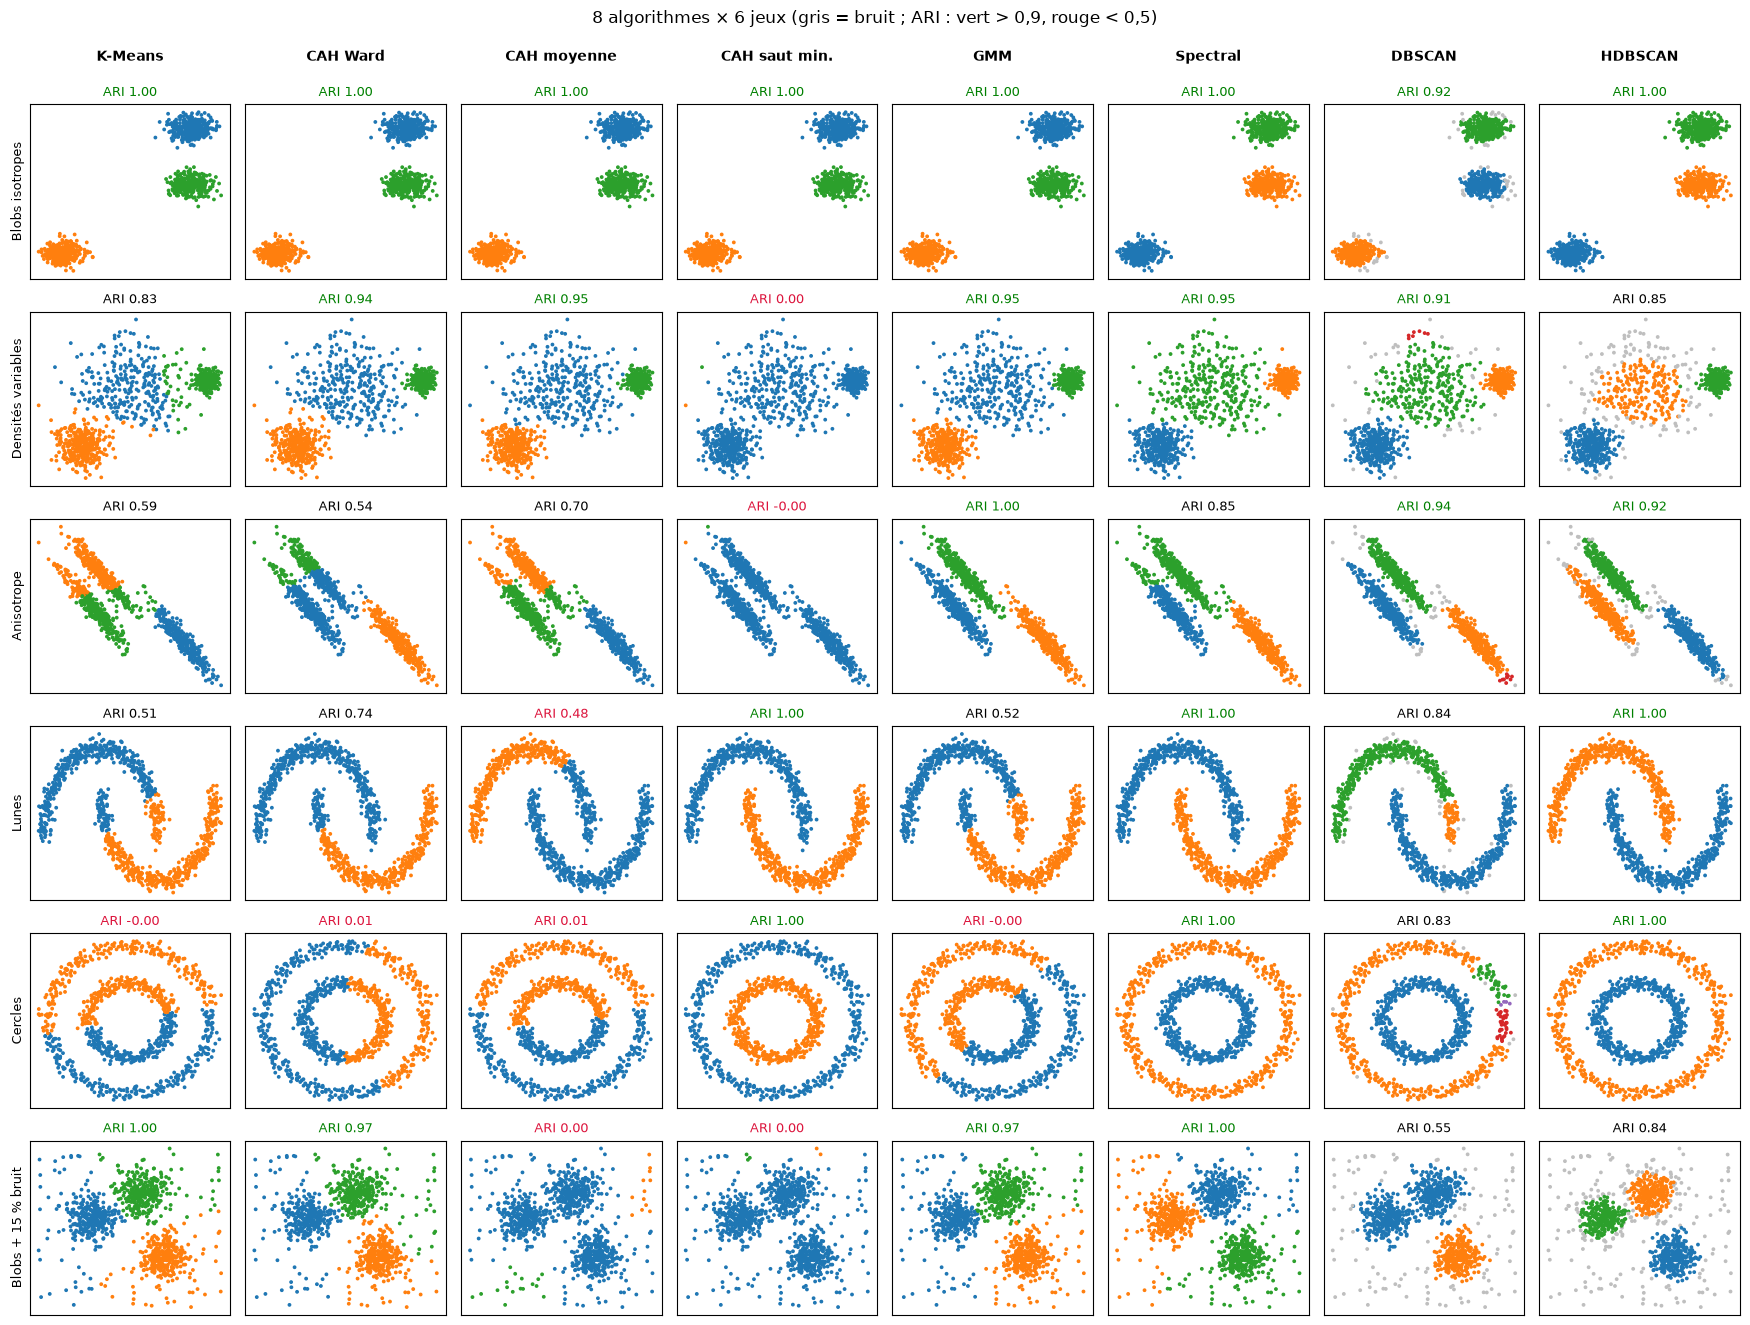

In [4]:
algos = list(make_algos(2, SYN["Lunes"][0]).keys())
fig, axes = plt.subplots(len(SYN), len(algos), figsize=(2.2 * len(algos), 2.2 * len(SYN)))
cmap = plt.get_cmap("tab10")
for i, (dname, (X, y, k)) in enumerate(SYN.items()):
    for j, aname in enumerate(algos):
        ax = axes[i, j]; lab = labels_store[(dname, aname)]
        colors = np.where(lab[:, None] == -1, np.array([[.75, .75, .75, 1]]), cmap(lab % 10))
        ax.scatter(X[:, 0], X[:, 1], c=colors, s=3)
        ari = syn[(syn.jeu == dname) & (syn.algo == aname)].ARI.iloc[0]
        ax.set_title(f"ARI {ari:.2f}", fontsize=9, color="green" if ari > .9 else "crimson" if ari < .5 else "black")
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.text(.5, 1.25, aname, transform=ax.transAxes, ha="center", fontsize=10, weight="bold")
        if j == 0: ax.set_ylabel(dname, fontsize=9)
plt.suptitle("8 algorithmes × 6 jeux (gris = bruit ; ARI : vert > 0,9, rouge < 0,5)", y=1.0)
plt.tight_layout(); plt.show()

In [5]:
ari_tab = syn.pivot(index="algo", columns="jeu", values="ARI").loc[algos, list(SYN)]
ari_tab["moyenne"] = ari_tab.mean(axis=1)
ari_tab.round(2).style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1).format("{:.2f}")

jeu,Blobs isotropes,Densités variables,Anisotrope,Lunes,Cercles,Blobs + 15 % bruit,moyenne
algo,,,,,,,
K-Means,1.00,0.83,0.59,0.51,-0.00,1.00,0.65
CAH Ward,1.00,0.94,0.54,0.74,0.01,0.97,0.70
CAH moyenne,1.00,0.95,0.70,0.48,0.01,0.00,0.52
CAH saut min.,1.00,0.00,-0.00,1.00,1.00,0.00,0.50
GMM,1.00,0.95,1.00,0.52,-0.00,0.97,0.74
Spectral,1.00,0.95,0.85,1.00,1.00,1.00,0.97
DBSCAN,0.92,0.91,0.94,0.84,0.83,0.55,0.83
HDBSCAN,1.00,0.85,0.92,1.00,1.00,0.84,0.93


**Analyse du banc d'essai** (ARI : 1 = partition parfaite, 0 = hasard).
- **Blobs isotropes** : presque tous les algorithmes obtiennent un ARI de 1. C'est le cas idéal de K-Means, et il ne permet pas de les départager.
- **Anisotrope** : K-Means (0,59) et Ward (0,54) échouent, car ils supposent des clusters sphériques. Le **GMM à covariance pleine** modélise les ellipses et atteint **1,00**.
- **Densités variables** : l'écart entre méthodes est faible (de 0,83 à 0,95). K-Means est le moins bon, car il découpe le cluster diffus pour équilibrer les inerties. DBSCAN s'en sort ici (0,91), mais en créant un **4e** cluster parasite : son $\varepsilon$ unique ne convient pas à la fois aux régions denses et diffuses.
- **Lunes et cercles** (formes non convexes) : les méthodes à centroïde **échouent** (K-Means, Ward et GMM entre 0 et 0,74). Les méthodes fondées sur la **connexité** atteignent **1,00** : saut minimal, spectral, HDBSCAN.
- **Bruit** : on calcule l'ARI sur les seuls vrais points des clusters. K-Means, Ward et GMM y sont bons, mais ils **affectent chaque point de bruit à un cluster** sans le signaler. **HDBSCAN** isole le bruit (21 % des points marqués, pour 15 % réellement injectés). DBSCAN fusionne deux clusters (ARI 0,55). Le **saut minimal s'effondre** (ARI 0) à cause de l'**effet de chaîne** : quelques points de bruit relient les clusters entre eux.
- **Bilan** : le **spectral** et **HDBSCAN** sont les plus polyvalents sur ce banc d'essai en 2D. Aucun algorithme n'est parfait partout. Le saut minimal, excellent sur les formes propres, est inutilisable dès qu'il y a du bruit.

<a id="3"></a>
## 3. Choisir le nombre de clusters et les paramètres

On utilise le jeu **Wine** de l'UCI : 178 vins italiens décrits par 13 mesures chimiques, issus de 3 cultivars. **Les étiquettes ne servent jamais à choisir les paramètres**, uniquement à évaluer à la fin, comme dans un vrai problème non supervisé.

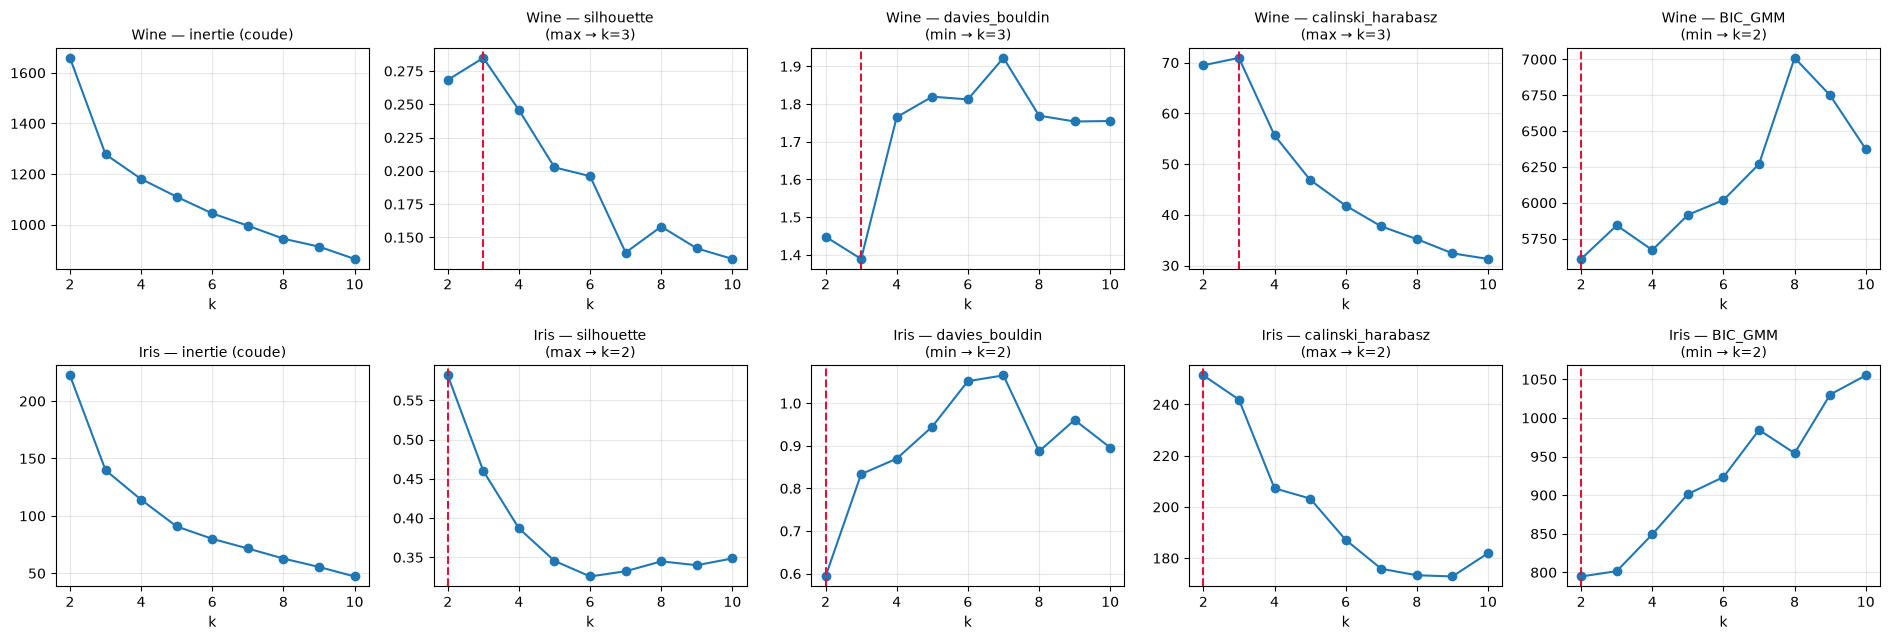

,Wine,Iris
silhouette,3,2
Davies-Bouldin,3,2
Calinski-Harabasz,3,2
BIC (GMM),2,2


In [6]:
wine = datasets.load_wine(as_frame=True)
Xw_raw, yw = wine.data, wine.target.values
Xw = StandardScaler().fit_transform(Xw_raw)
iris = datasets.load_iris()
Xi, yi = StandardScaler().fit_transform(iris.data), iris.target

def k_selection(X, ks=range(2, 11)):
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        gm = GaussianMixture(n_components=k, covariance_type="full", random_state=SEED, n_init=3).fit(X)
        rows.append(dict(k=k, inertie=km.inertia_, silhouette=silhouette_score(X, km.labels_),
                         davies_bouldin=davies_bouldin_score(X, km.labels_),
                         calinski_harabasz=calinski_harabasz_score(X, km.labels_), BIC_GMM=gm.bic(X)))
    return pd.DataFrame(rows).set_index("k")

sel_w, sel_i = k_selection(Xw), k_selection(Xi)
fig, axes = plt.subplots(2, 5, figsize=(19, 6.5))
for r, (name, sel) in enumerate([("Wine", sel_w), ("Iris", sel_i)]):
    for c, (col, best) in enumerate([("inertie", None), ("silhouette", "max"), ("davies_bouldin", "min"),
                                     ("calinski_harabasz", "max"), ("BIC_GMM", "min")]):
        ax = axes[r, c]; ax.plot(sel.index, sel[col], "o-")
        if best:
            kb = sel[col].idxmax() if best == "max" else sel[col].idxmin()
            ax.axvline(kb, color="crimson", ls="--"); ax.set_title(f"{name} — {col}\n({best} → k={kb})", fontsize=10)
        else:
            ax.set_title(f"{name} — {col} (coude)", fontsize=10)
        ax.grid(alpha=.3); ax.set_xlabel("k")
plt.tight_layout(); plt.show()
best_k = pd.DataFrame({name: {"silhouette": s.silhouette.idxmax(), "Davies-Bouldin": s.davies_bouldin.idxmin(),
                              "Calinski-Harabasz": s.calinski_harabasz.idxmax(), "BIC (GMM)": s.BIC_GMM.idxmin()}
                       for name, s in [("Wine", sel_w), ("Iris", sel_i)]})
best_k

**Lecture.**
- Sur **Wine**, la silhouette, Davies-Bouldin et Calinski-Harabasz choisissent tous **k = 3**, ce qui correspond au nombre réel de cultivars, que l'algorithme n'a jamais vu.
- Sur **Iris**, les trois critères préfèrent **k = 2**, alors qu'il y a 3 espèces. Ce n'est pas une erreur des critères : *setosa* est très séparée, tandis que *versicolor* et *virginica* se chevauchent. **La structure la plus nette dans les données est bien en 2 groupes.** C'est une leçon importante : les critères internes mesurent la **séparation géométrique**, pas la concordance avec une classification « métier ».
- Le **BIC** du GMM choisit **k = 2 sur les deux jeux**. Une composante à covariance pleine en dimension 13 coûte $13 + 13 \cdot 14/2 = 104$ paramètres, ce que le BIC pénalise fortement pour 178 points. Avec peu de données en grande dimension, le BIC d'un GMM « plein » **sous-estime** $k$. Il faudrait des covariances diagonales ou partagées (`covariance_type="diag"` ou `"tied"`).

Sauts de hauteur entre fusions successives (du haut vers le bas) : [ 7.7 15.1  0.3  0.5  0.3  1.   0.2  1.9]


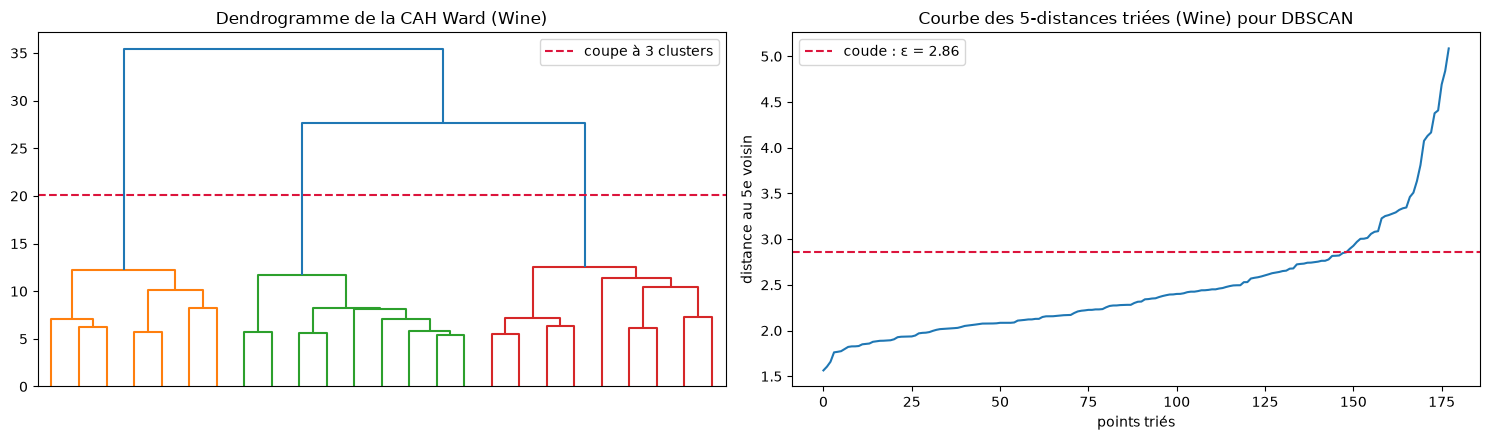

DBSCAN ε=2.28 : 2 clusters, 24% de bruit, ARI=0.39
DBSCAN ε=2.86 : 1 clusters, 7% de bruit, ARI=-0.01


DBSCAN ε=3.43 : 1 clusters, 4% de bruit, ARI=-0.01
DBSCAN ε=4.00 : 1 clusters, 2% de bruit, ARI=-0.01


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
Z = linkage(Xw, method="ward")
dendrogram(Z, truncate_mode="lastp", p=25, ax=axes[0], color_threshold=Z[-3, 2] + 1e-9, no_labels=True)
axes[0].axhline(Z[-3, 2] + 0.5 * (Z[-2, 2] - Z[-3, 2]), color="crimson", ls="--", label="coupe à 3 clusters")
axes[0].set_title("Dendrogramme de la CAH Ward (Wine)"); axes[0].legend()
gaps = np.diff(Z[::-1, 2])[:8]
print("Sauts de hauteur entre fusions successives (du haut vers le bas) :", np.round(-gaps, 1))

eps_w, kd = kdist_eps(Xw)
axes[1].plot(kd); axes[1].axhline(eps_w, color="crimson", ls="--", label=f"coude : ε = {eps_w:.2f}")
axes[1].set_title("Courbe des 5-distances triées (Wine) pour DBSCAN"); axes[1].legend()
axes[1].set_xlabel("points triés"); axes[1].set_ylabel("distance au 5e voisin")
plt.tight_layout(); plt.show()

for eps in [eps_w * f for f in (0.8, 1.0, 1.2, 1.4)]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Xw)
    print(f"DBSCAN ε={eps:.2f} : {len(set(lab) - {-1})} clusters, {np.mean(lab == -1):.0%} de bruit, "
          f"ARI={adjusted_rand_score(yw, lab):.2f}")

**Dendrogramme et DBSCAN en dimension 13.**
- Le dendrogramme de Ward montre deux **grands sauts** de hauteur (15,1 puis 7,7), puis des sauts inférieurs à 2. La coupe naturelle est donc à **3 clusters**, en accord avec les critères précédents.
- **DBSCAN n'arrive pas à structurer Wine.** Avec le $\varepsilon$ du coude, il ne trouve qu'**un seul cluster**. En réduisant $\varepsilon$, il en trouve 2, mais classe 24 % des vins en bruit (ARI 0,39). Il n'existe pas de valeur intermédiaire satisfaisante. C'est la **malédiction de la dimension** : en dimension 13, les distances se concentrent, et l'écart de densité entre « dans un cluster » et « entre les clusters » s'amenuise. Les méthodes fondées sur la densité sont à privilégier en faible dimension, ou après une réduction de dimension.

<a id="4"></a>
## 4. L'effet de la standardisation

In [8]:
print("Écarts-types des variables brutes (Wine) :")
print(Xw_raw.std().sort_values(ascending=False).round(2).head(4).to_string())
rows = []
for name, X in [("brutes", Xw_raw.values), ("standardisées", Xw)]:
    for aname, algo in [("K-Means", KMeans(3, n_init=10, random_state=SEED)),
                        ("CAH Ward", AgglomerativeClustering(3, linkage="ward")),
                        ("GMM", GaussianMixture(3, random_state=SEED))]:
        lab = algo.fit_predict(X)
        rows.append(dict(données=name, algo=aname, ARI=adjusted_rand_score(yw, lab)))
pd.DataFrame(rows).pivot(index="algo", columns="données", values="ARI").round(3)

Écarts-types des variables brutes (Wine) :
proline              314.91
magnesium             14.28
alcalinity_of_ash      3.34
color_intensity        2.32


données,brutes,standardisées
algo,,
CAH Ward,0.368,0.790
GMM,0.607,0.897
K-Means,0.371,0.897


**Résultat décisif.** Sur les variables brutes, `proline` a un écart-type de 315, contre 14 pour la variable suivante et moins de 4 pour toutes les autres. La distance euclidienne ne « voit » qu'elle :
- l'ARI de K-Means passe de **0,37** sur les variables brutes à **0,90** après standardisation ;
- celui de Ward passe de 0,37 à 0,79.

Le GMM à covariance pleine est **moins sensible** à l'échelle (0,61 sur les variables brutes), puisqu'il apprend la covariance de chaque composante. Il profite tout de même beaucoup de la standardisation (0,90).

**Règle** : pour toute méthode fondée sur une distance, on standardise dès que les variables n'ont pas la même unité.

<a id="5"></a>
## 5. Comparaison quantitative sur Iris et Wine

On évalue avec deux familles de critères :
- **internes**, sans étiquettes : silhouette (↑), Davies-Bouldin (↓), Calinski-Harabasz (↑) ;
- **externes**, avec les étiquettes, à titre de contrôle : ARI et NMI.

On fixe $k = 3$ pour les méthodes qui le demandent, d'après la partie 3 pour Wine et d'après le nombre d'espèces pour Iris. Pour HDBSCAN, on prend une taille minimale de cluster adaptée à ces petits jeux (`min_cluster_size=10`).

In [9]:
def evaluate(X, y, k):
    rows = []
    algos = make_algos(k, X); algos["HDBSCAN"] = HDBSCAN(min_cluster_size=10)
    for aname, algo in algos.items():
        lab, t = fit_predict(algo, X)
        core = lab != -1
        ok = len(set(lab[core])) >= 2
        rows.append(dict(algo=aname, n_clusters=len(set(lab) - {-1}), bruit=np.mean(~core),
                         silhouette=silhouette_score(X[core], lab[core]) if ok else np.nan,
                         davies_bouldin=davies_bouldin_score(X[core], lab[core]) if ok else np.nan,
                         calinski_harabasz=calinski_harabasz_score(X[core], lab[core]) if ok else np.nan,
                         ARI=adjusted_rand_score(y, lab), NMI=normalized_mutual_info_score(y, lab), temps_ms=1000 * t))
    return pd.DataFrame(rows).set_index("algo")

comp = {name: evaluate(X, y, 3) for name, X, y in [("Iris", Xi, yi), ("Wine", Xw, yw)]}
for name, tab in comp.items():
    print(f"===== {name} =====")
    display(tab.round(3).style.background_gradient(subset=["ARI", "NMI", "silhouette"], cmap="RdYlGn", vmin=0, vmax=1)
            .format("{:.3f}", subset=["bruit", "silhouette", "davies_bouldin", "ARI", "NMI"])
            .format("{:.1f}", subset=["calinski_harabasz", "temps_ms"]))

===== Iris =====


,n_clusters,bruit,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,temps_ms
algo,,,,,,,,
K-Means,3,0.000,0.460,0.834,241.9,0.620,0.659,123.9
CAH Ward,3,0.000,0.447,0.803,222.7,0.615,0.675,0.9
CAH moyenne,3,0.000,0.480,0.575,149.0,0.562,0.713,0.9
CAH saut min.,3,0.000,0.505,0.493,131.5,0.558,0.720,0.7
GMM,3,0.000,0.374,1.081,187.8,0.904,0.900,12.8
Spectral,3,0.000,0.403,0.865,178.0,0.476,0.524,6.4
DBSCAN,2,0.027,0.598,0.569,277.7,0.552,0.690,1.4
HDBSCAN,2,0.013,0.590,0.585,266.4,0.564,0.717,1.8


===== Wine =====


,n_clusters,bruit,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,temps_ms
algo,,,,,,,,
K-Means,3,0.000,0.285,1.389,70.9,0.897,0.876,7.2
CAH Ward,3,0.000,0.277,1.419,67.6,0.790,0.786,1.4
CAH moyenne,3,0.000,0.158,1.030,4.0,-0.005,0.018,1.2
CAH saut min.,3,0.000,0.183,0.911,4.1,-0.007,0.035,1.2
GMM,3,0.000,0.285,1.389,70.9,0.897,0.876,26.3
Spectral,3,0.000,0.283,1.391,70.0,0.880,0.861,8.0
DBSCAN,1,0.073,nan,nan,nan,-0.006,0.063,3.1
HDBSCAN,2,0.421,0.363,1.046,59.3,0.260,0.354,3.7


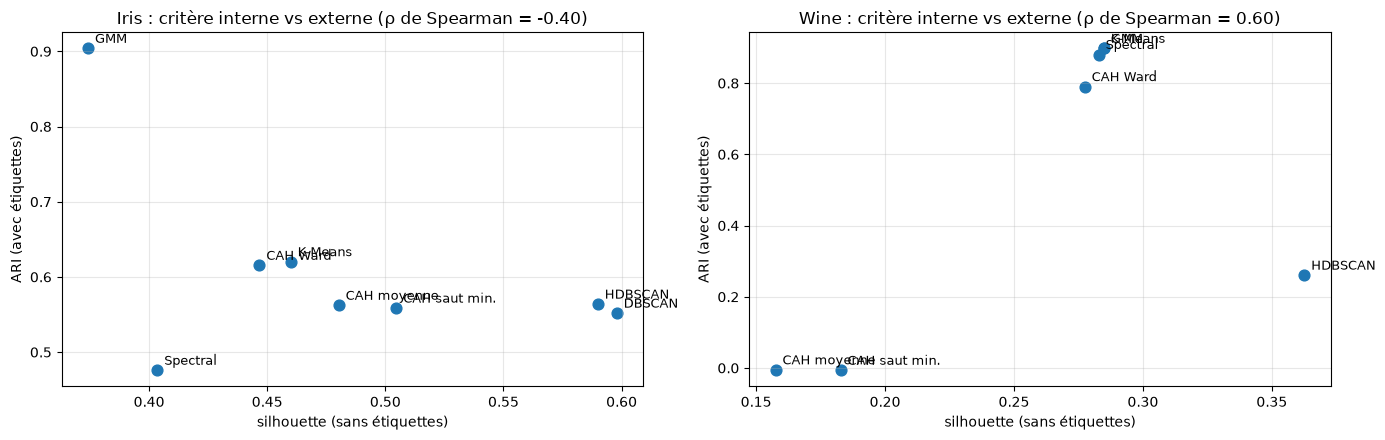

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, tab) in zip(axes, comp.items()):
    t = tab.dropna(subset=["silhouette"])
    ax.scatter(t.silhouette, t.ARI, s=60)
    for a, r in t.iterrows():
        ax.annotate(a, (r.silhouette, r.ARI), textcoords="offset points", xytext=(5, 4), fontsize=9)
    rho = t[["silhouette", "ARI"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{name} : critère interne vs externe (ρ de Spearman = {rho:.2f})")
    ax.set_xlabel("silhouette (sans étiquettes)"); ax.set_ylabel("ARI (avec étiquettes)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Analyse.**
- **Wine** : K-Means et GMM (ARI **0,90**), puis le spectral (0,88) et Ward (0,79), retrouvent bien les 3 cultivars. Ce sont aussi ceux qui ont la meilleure silhouette parmi les méthodes à 3 clusters.
  - Les CAH **moyenne** et **saut minimal** échouent complètement (ARI ≈ 0) : un énorme cluster et deux singletons, l'effet de chaîne.
  - **DBSCAN** ne trouve qu'un cluster.
  - **HDBSCAN** trouve 2 clusters mais déclare **42 %** des vins comme bruit. Sa silhouette (0,36), calculée sur les seuls points conservés, paraît alors excellente : c'est un **piège**. On ne peut pas comparer des silhouettes calculées sur des sous-ensembles de points différents.
- **Iris** : le **GMM écrase les autres** (ARI **0,90**, contre 0,62 pour K-Means). *Versicolor* et *virginica* forment deux ellipses allongées qui se chevauchent, cas où les covariances libres et l'affectation probabiliste font la différence.
- **Critères interne et externe peuvent se contredire.** Sur Iris, la meilleure silhouette revient à DBSCAN et HDBSCAN (environ 0,6), qui ne trouvent que **2** clusters, alors que le GMM, le meilleur en ARI, a la **plus faible** silhouette (0,37). La silhouette récompense la séparation géométrique (setosa contre le reste), pas la partition « métier ». Elle guide le choix *en l'absence* d'étiquettes, mais ne remplace pas une validation par un expert.

<a id="6"></a>
## 6. Stabilité par ré-échantillonnage

Un bon clustering doit être **reproductible** : sur deux sous-échantillons de 80 % des données, il doit donner des partitions similaires sur les points communs. On répète 30 fois et on mesure l'ARI entre partitions, **sans utiliser les étiquettes**.

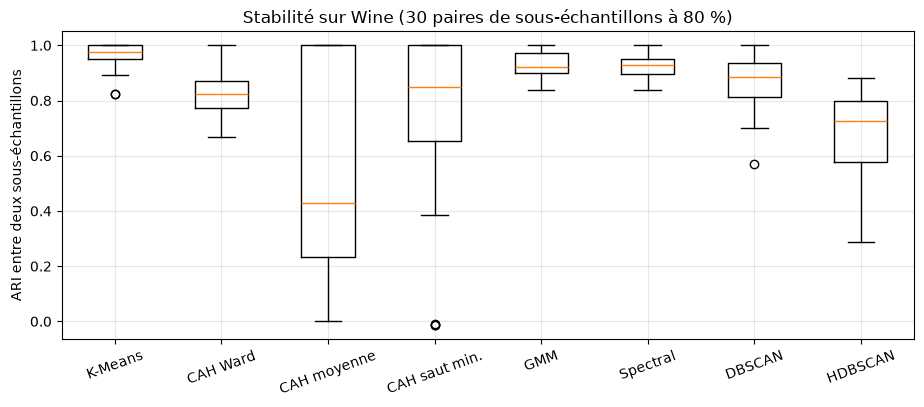

,mean,std
K-Means,0.967,0.049
GMM,0.927,0.048
Spectral,0.925,0.043
DBSCAN,0.869,0.108
CAH Ward,0.819,0.088
CAH saut min.,0.749,0.321
HDBSCAN,0.675,0.155
CAH moyenne,0.537,0.395


In [11]:
def stability(X, k, n_rep=30, frac=0.8):
    rng = np.random.RandomState(SEED); n = len(X); out = {}
    names = list(make_algos(k, X).keys())
    for aname in names:
        scores = []
        for _ in range(n_rep):
            a = rng.choice(n, int(frac * n), replace=False); b = rng.choice(n, int(frac * n), replace=False)
            common = np.intersect1d(a, b)
            la = pd.Series(fit_predict(make_algos(k, X[a])[aname] if aname != "HDBSCAN" else HDBSCAN(min_cluster_size=10), X[a])[0], index=a)
            lb = pd.Series(fit_predict(make_algos(k, X[b])[aname] if aname != "HDBSCAN" else HDBSCAN(min_cluster_size=10), X[b])[0], index=b)
            scores.append(adjusted_rand_score(la[common], lb[common]))
        out[aname] = scores
    return pd.DataFrame(out)

stab = stability(Xw, 3)
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(stab.values); ax.set_xticks(range(1, stab.shape[1] + 1)); ax.set_xticklabels(stab.columns); ax.set_ylabel("ARI entre deux sous-échantillons")
ax.set_title("Stabilité sur Wine (30 paires de sous-échantillons à 80 %)"); ax.grid(alpha=.3)
plt.xticks(rotation=20); plt.show()
stab.agg(["mean", "std"]).T.sort_values("mean", ascending=False).round(3)

**Lecture.**
- **K-Means est le plus stable** (ARI moyen de 0,97), suivi du GMM et du spectral (environ 0,93).
- Ward est un peu moins stable (0,82) : une fusion hiérarchique est **définitive**, et une erreur en début d'agrégation se propage jusqu'à la coupe.
- Les CAH **moyenne** (0,54 ± 0,40) et **saut minimal** (0,75 ± 0,32) sont très **instables**, avec une forte variance : selon l'échantillon, une chaîne se forme ou non.
- **HDBSCAN** est instable (0,68), car la frontière entre cluster et bruit bouge d'un échantillon à l'autre.
- La bonne note de **DBSCAN** (0,87) est **trompeuse** : il produit presque toujours un seul cluster, et une partition triviale est forcément stable. La stabilité est **nécessaire, mais pas suffisante**.

La stabilité est un **critère de choix non supervisé** complémentaire de la silhouette : un algorithme qui change d'avis selon l'échantillon ne produit pas une structure fiable.

<a id="7"></a>
## 7. Passage à l'échelle

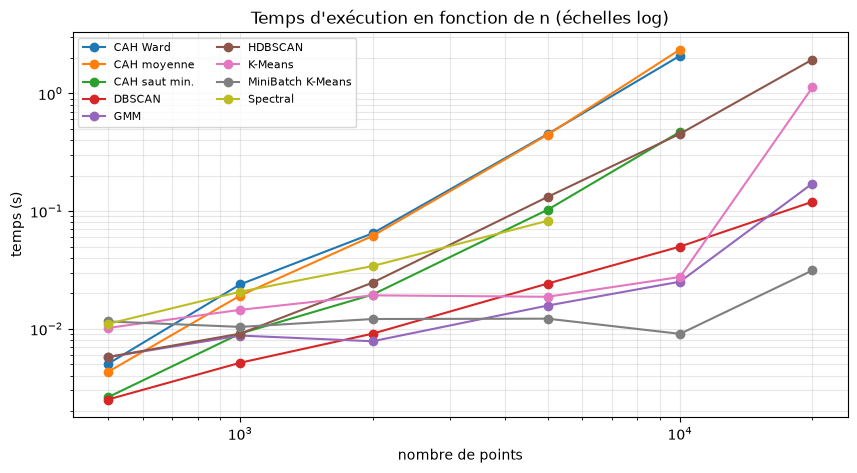

n,500,1000,2000,5000,10000,20000
algo,,,,,,
CAH Ward,0.005,0.024,0.065,0.451,2.087,NaN
CAH moyenne,0.004,0.019,0.062,0.445,2.356,NaN
CAH saut min.,0.003,0.009,0.020,0.103,0.472,NaN
DBSCAN,0.003,0.005,0.009,0.024,0.050,0.120
GMM,0.006,0.009,0.008,0.016,0.025,0.171
HDBSCAN,0.006,0.009,0.025,0.132,0.454,1.938
K-Means,0.010,0.014,0.019,0.019,0.028,1.123
MiniBatch K-Means,0.012,0.010,0.012,0.012,0.009,0.031
Spectral,0.011,0.021,0.034,0.083,NaN,NaN


In [12]:
sizes = [500, 1000, 2000, 5000, 10000, 20000]
limits = {"CAH Ward": 10000, "CAH moyenne": 10000, "CAH saut min.": 10000, "Spectral": 5000}
timing = []
for n_pts in sizes:
    X, _ = datasets.make_blobs(n_samples=n_pts, centers=5, n_features=2, random_state=SEED)
    X = StandardScaler().fit_transform(X)
    algos = make_algos(5, X); algos["MiniBatch K-Means"] = MiniBatchKMeans(5, n_init=3, random_state=SEED)
    for aname, algo in algos.items():
        if n_pts > limits.get(aname, np.inf):
            continue
        timing.append(dict(n=n_pts, algo=aname, temps=fit_predict(algo, X)[1]))
timing = pd.DataFrame(timing)
fig, ax = plt.subplots(figsize=(10, 5))
for aname, g in timing.groupby("algo"):
    ax.plot(g.n, g.temps, "o-", label=aname)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("nombre de points"); ax.set_ylabel("temps (s)")
ax.set_title("Temps d'exécution en fonction de n (échelles log)"); ax.grid(alpha=.3, which="both"); ax.legend(fontsize=8, ncol=2)
plt.show()
timing.pivot(index="algo", columns="n", values="temps").round(3)

**Analyse.** Sur une échelle log-log, la pente d'une courbe donne l'exposant de la complexité.
- **La CAH est quadratique** : de 5 000 à 10 000 points, le temps de Ward est multiplié par environ 4,6 (de 0,46 s à 2,1 s), comme attendu pour du $O(n^2)$. La matrice des distances interdit en pratique d'aller beaucoup plus loin. Le saut minimal est plus rapide, car il revient à un arbre couvrant minimal.
- **HDBSCAN** est sur-linéaire (2 s pour 20 000 points), mais reste utilisable.
- **DBSCAN, GMM et MiniBatch K-Means** restent sous 0,2 s à 20 000 points. **MiniBatch K-Means** est le plus rapide (0,03 s), car il ne voit qu'un échantillon des points à chaque itération.
- **K-Means** est très rapide jusqu'à 10 000 points. Le saut à environ 1 s pour 20 000 points s'explique par ses 10 initialisations (`n_init=10`) et par la parallélisation, d'où l'intérêt de MiniBatch à grande échelle.
- Le **spectral** reste raisonnable ici (0,08 s pour 5 000 points), grâce à un graphe des 10 plus proches voisins **creux**. Avec une affinité dense (noyau RBF sur toutes les paires), il deviendrait $O(n^2)$ en mémoire et $O(n^3)$ en temps.

**Choix** : pour de grands volumes, on utilise MiniBatch K-Means ou K-Means pour des clusters globulaires, et HDBSCAN pour des formes quelconques avec du bruit. La CAH est à réserver aux jeux de taille modérée, ou à appliquer à un échantillon.

<a id="8"></a>
## 8. Interprétation du clustering retenu (Wine)

**Choix argumenté pour Wine**, fondé uniquement sur des critères non supervisés :
1. les variables sont standardisées (partie 4) ;
2. on prend $k = 3$, valeur sur laquelle s'accordent la silhouette, Davies-Bouldin, Calinski-Harabasz et le dendrogramme (partie 3) ;
3. parmi les méthodes à 3 clusters, K-Means, GMM et spectral ont la meilleure silhouette (environ 0,28), et **K-Means est le plus stable** (0,97, partie 6) ;
4. à qualité égale, on préfère le modèle le plus **simple et interprétable** (des centroïdes) et le plus **rapide**.

On retient donc **K-Means**. Le GMM donne la même partition, mais il est plus coûteux et a davantage de paramètres. Ward, moins stable, sert de point de comparaison.

Accord K-Means / GMM : ARI = 1.000 ; K-Means / Ward : 0.853
K-Means vs cultivars (contrôle a posteriori) : ARI = 0.897


cultivar,class_0,class_1,class_2
cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


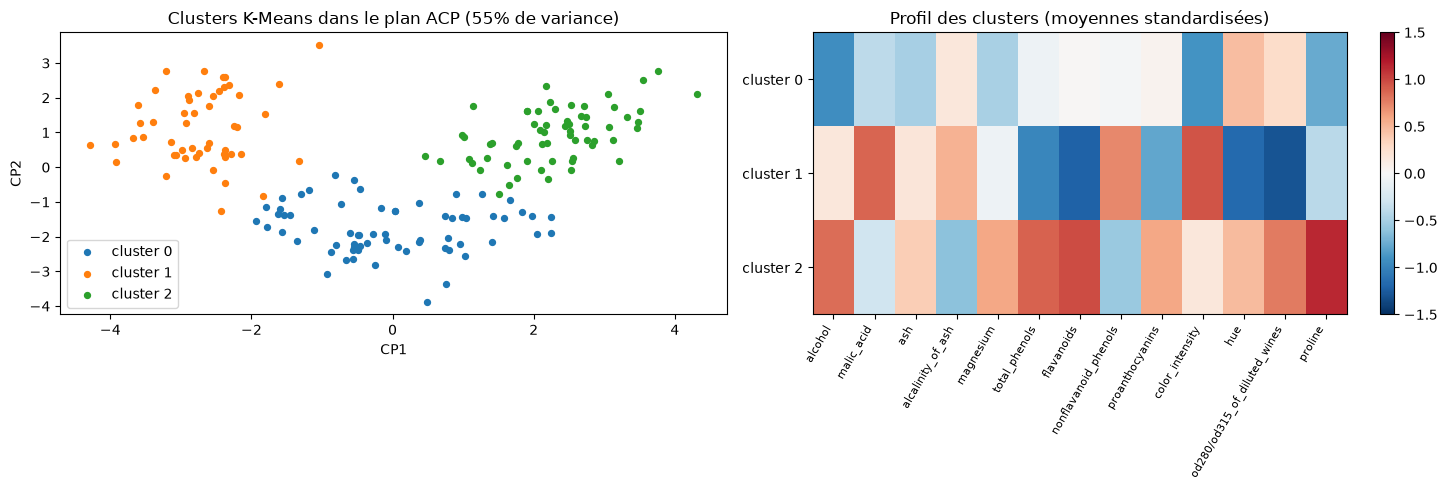

cluster 0 : élevé en hue, od280/od315_of_diluted_wines, alcalinity_of_ash ; faible en alcohol, color_intensity
cluster 1 : élevé en color_intensity, malic_acid, nonflavanoid_phenols ; faible en od280/od315_of_diluted_wines, flavanoids
cluster 2 : élevé en proline, flavanoids, total_phenols ; faible en alcalinity_of_ash, nonflavanoid_phenols


In [13]:
lab_w = KMeans(3, n_init=10, random_state=SEED).fit_predict(Xw)
ward_w = AgglomerativeClustering(3, linkage="ward").fit_predict(Xw)
gmm_w = GaussianMixture(3, random_state=SEED).fit_predict(Xw)
print(f"Accord K-Means / GMM : ARI = {adjusted_rand_score(lab_w, gmm_w):.3f} ; K-Means / Ward : {adjusted_rand_score(lab_w, ward_w):.3f}")
print(f"K-Means vs cultivars (contrôle a posteriori) : ARI = {adjusted_rand_score(yw, lab_w):.3f}")
display(pd.crosstab(pd.Series(lab_w, name="cluster"), pd.Series(wine.target_names[yw], name="cultivar")))

pca = PCA(2).fit(Xw); P = pca.transform(Xw)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c in range(3):
    axes[0].scatter(P[lab_w == c, 0], P[lab_w == c, 1], s=18, label=f"cluster {c}")
axes[0].set_title(f"Clusters K-Means dans le plan ACP ({pca.explained_variance_ratio_.sum():.0%} de variance)")
axes[0].set_xlabel("CP1"); axes[0].set_ylabel("CP2"); axes[0].legend()

prof = pd.DataFrame(Xw, columns=wine.feature_names).groupby(lab_w).mean()
im = axes[1].imshow(prof.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
axes[1].set_xticks(range(len(prof.columns))); axes[1].set_xticklabels(prof.columns, rotation=60, ha="right", fontsize=8)
axes[1].set_yticks(range(3)); axes[1].set_yticklabels([f"cluster {c}" for c in range(3)])
axes[1].set_title("Profil des clusters (moyennes standardisées)"); plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

for c in range(3):
    top = prof.loc[c].sort_values()
    print(f"cluster {c} : élevé en {', '.join(top.index[-3:][::-1])} ; faible en {', '.join(top.index[:2])}")

**Interprétation.** La table de contingence montre que chaque cluster correspond très majoritairement à **un cultivar**, avec seulement quelques vins mal placés. Les erreurs concernent le cultivar `class_1`, le plus hétérogène, qui se trouve au centre du plan de l'ACP. Les clusters ont un **profil chimique** distinct :
- un groupe riche en **proline, flavonoïdes et phénols** (`class_0`) ;
- un groupe **peu alcoolisé** et à **faible intensité de couleur** (`class_1`) ;
- un groupe à **forte intensité de couleur** et riche en acide malique, mais **pauvre en flavonoïdes** (`class_2`).

Le clustering a retrouvé, **sans supervision**, une structure qui a un sens œnologique. Le profil des centroïdes donne une **description intelligible** de chaque groupe, que l'on pourrait présenter à un expert.

<a id="9"></a>
## 9. Synthèse et choix

### Tableau de décision

| Situation | Choix recommandé | Pourquoi | À éviter |
|---|---|---|---|
| Clusters compacts, $k$ estimable, gros volume | **K-Means** (MiniBatch si très gros) | rapide, stable, simple à interpréter (centroïdes) | saut minimal |
| Clusters elliptiques, tailles ou variances différentes, besoin de probabilités | **GMM à covariance pleine** | modélise les ellipses ; BIC pour choisir $k$ ; affectation douce | K-Means |
| Taille modérée, besoin d'une hiérarchie | **CAH Ward** | dendrogramme, choix de $k$ a posteriori | CAH au-delà de 10⁴ points |
| Formes non convexes, faible dimension | **Spectral** ou **HDBSCAN** | connexité et densité | K-Means, Ward, GMM |
| Bruit ou points aberrants, $k$ inconnu | **HDBSCAN** | trouve $k$, isole le bruit, tolère des densités variables | DBSCAN avec un seul ε si les densités varient |
| Haute dimension | standardiser, réduire (ACP), puis **K-Means / GMM** | les distances se concentrent | DBSCAN sur les données brutes |

### Choix pour nos jeux
- **Wine** : standardisation, puis **K-Means** avec $k=3$. Les critères internes, le dendrogramme et la stabilité (0,97) convergent, et l'ARI vaut 0,90 a posteriori.
- **Iris** : la structure géométrique la plus nette est en **2 groupes**. Pour retrouver les 3 espèces, le **GMM** est de loin le plus adapté (ARI 0,90 contre 0,62 pour K-Means), car versicolor et virginica forment des ellipses qui se chevauchent.
- **Données à formes arbitraires et bruitées** (lunes, cercles, bruit) : **HDBSCAN**, qui ne demande pas $k$ et ne force pas les points aberrants dans un cluster.

### À retenir
1. Chaque algorithme encode une **hypothèse de forme**, et c'est elle qu'il faut choisir en premier.
2. Le **prétraitement** (standardisation) peut compter davantage que le choix de l'algorithme.
3. Les critères **internes** (silhouette…) servent à choisir les paramètres sans étiquettes, mais ils mesurent la séparation géométrique, pas le sens métier.
4. La **stabilité** et le **coût** sont des critères de choix aussi importants que la qualité.

**Compétences mobilisées** : scikit-learn, apprentissage non supervisé, sélection de modèle (silhouette, BIC, dendrogramme, k-distances), évaluation interne et externe, bootstrap, analyse de complexité, ACP et interprétation des résultats.